# Tutorial: predict unmeasured genes in a fetal-heart MERFISH section

This notebook downloads a small public dataset, fits RESONATE on a CPU, scores it on measured genes hidden from the
model, and predicts genes that the panel did not measure. The outputs below come from one run of this notebook, top to
bottom, in a new environment on 4 CPU cores. It took 7.6 min (`prepare` 0.9 min, `fit` 6.3 min) and at most 9.9 GiB of memory. Download it (button at the top of the page, or
[from GitHub](https://github.com/J041120h/RESONATE_tutorial/blob/main/docs/tutorials/walkthrough.ipynb)) and run it in an
empty folder.

**Install** ([details](https://j041120h.github.io/RESONATE_tutorial/installation/)); use a machine with at least 16 GB of RAM:

```bash
pip install torch --index-url https://download.pytorch.org/whl/cpu
pip install "resonate-st[notebook] @ git+https://github.com/J041120h/RESONATE.git"
```

## 1. Download the demo data

About 12 MB from the code repository's `sample_data/` folder (on macOS, use `shasum -a 256 -c` instead of `sha256sum -c`).

In [1]:
%%bash
mkdir -p data
cd data
BASE=https://raw.githubusercontent.com/J041120h/RESONATE/main/sample_data
for f in fetal_heart_spatial.h5ad fetal_heart_reference.h5ad scgpt_spatial_embeddings_subset.npz \
         held_out_genes.txt sample_info.json SHA256SUMS; do
    curl -fsSLO "$BASE/$f"
done
sha256sum -c SHA256SUMS

fetal_heart_reference.h5ad: OK
fetal_heart_spatial.h5ad: OK
held_out_genes.txt: OK
sample_info.json: OK
scgpt_spatial_embeddings_subset.npz: OK


Data: Farah *et al.*, *Nature* 2024 (CC0 1.0). Gene embeddings: scGPT-spatial, Wang *et al.*, bioRxiv 2025 (CC BY 4.0).

## 2. Look at the inputs

A MERFISH window of a 13-week fetal heart (raw counts of 236 genes), a single-cell reference of the same study (raw
counts of 2,244 genes), one scGPT-spatial embedding per gene, and 48 panel genes that we hide from the model.

In [2]:
import time

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.colors import LinearSegmentedColormap

import resonate

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 9, "font.size": 8})
TEAL, GREY = "#0b6f5d", "#d5dadf"
RAMP = LinearSegmentedColormap.from_list("ramp", ["#eef2f3", "#9fdcc9", "#10b396", "#0b6f5d", "#0b3b35"])

spatial = ad.read_h5ad("data/fetal_heart_spatial.h5ad")
reference = ad.read_h5ad("data/fetal_heart_reference.h5ad")
emb = resonate.load_gene_embeddings("data/scgpt_spatial_embeddings_subset.npz")
held_out = open("data/held_out_genes.txt").read().split()
print(spatial, "\n")
print(reference, "\n")
print(f"{len(emb)} gene embeddings; {len(held_out)} held-out genes; resonate {resonate.__version__}")

AnnData object with n_obs × n_vars = 12000 × 236
    obs: 'section', 'stage', 'author_fine', 'split'
    obsm: 'spatial' 

AnnData object with n_obs × n_vars = 8011 × 2244
    obs: 'donor', 'author_label' 

2244 gene embeddings; 48 held-out genes; resonate 0.1.0


`author_fine` holds the authors' cell types. RESONATE does not use them; we group them only to read the plots.

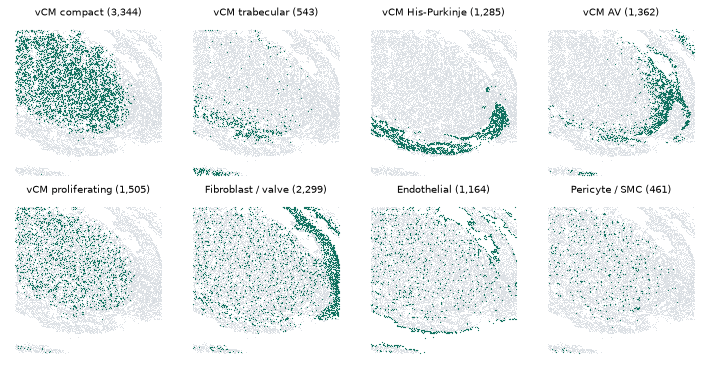

In [3]:
GROUPS = {
    "vCM compact": ["vCM-LV-Compact", "vCM-RV-Compact"],
    "vCM trabecular": ["vCM-LV-Trabecular", "vCM-RV-Trabecular"],
    "vCM His-Purkinje": ["vCM-His-Purkinje"],
    "vCM AV": ["vCM-LV-AV", "vCM-RV-AV"],
    "vCM proliferating": ["vCM-Proliferating"],
    "Fibroblast / valve": ["VIC", "vFibro", "aFibro", "EPDC"],
    "Endothelial": ["BEC", "VEC", "vEndocardial", "aEndocardial", "LEC"],
    "Pericyte / SMC": ["Pericyte", "VSMC"],
}
to_group = {label: group for group, labels in GROUPS.items() for label in labels}
group = spatial.obs["author_fine"].astype(str).map(to_group).fillna("Other").to_numpy()
xy = spatial.obsm["spatial"]

fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for ax, name in zip(axes.ravel(), GROUPS):
    m = group == name
    ax.scatter(xy[~m, 0], xy[~m, 1], s=0.5, c=GREY, linewidths=0)
    ax.scatter(xy[m, 0], xy[m, 1], s=1.2, c=TEAL, linewidths=0)
    ax.set_title(f"{name} ({m.sum():,})")
    ax.set_aspect("equal")
    ax.axis("off")
fig.tight_layout()
plt.show()

## 3. Prepare, fit and predict

`target_genes=held_out` removes the 48 genes from the spatial input and keeps their measured values for scoring. The
settings run on a CPU with at most 12 epochs per training stage; on a GPU, use `resonate.Config()`.

In [4]:
cfg = resonate.Config(device="cpu", tf32=False, attn_bf16=False, max_epochs=12)

t0 = time.time()
prep = resonate.prepare(spatial, reference, emb, target_genes=held_out, config=cfg)
print(prep)
print(f"prepare took {(time.time() - t0) / 60:.1f} min")

22:23:14 panel 236 genes = 188 measured + 48 targets (48 held out from the input)
22:23:14 12000 spatial cells (9600/1265/1135 train/val/test), 8011 reference cells, 4 reference batch(es), device cpu
22:23:16   lookup fold 1/20
22:23:16   lookup fold 2/20
22:23:16   lookup fold 3/20
22:23:17   lookup fold 4/20
22:23:17   lookup fold 5/20
22:23:18   lookup fold 6/20
22:23:18   lookup fold 7/20
22:23:18   lookup fold 8/20
22:23:19   lookup fold 9/20
22:23:19   lookup fold 10/20
22:23:20   lookup fold 11/20
22:23:20   lookup fold 12/20
22:23:20   lookup fold 13/20
22:23:21   lookup fold 14/20
22:23:21   lookup fold 15/20
22:23:22   lookup fold 16/20
22:23:22   lookup fold 17/20
22:23:22   lookup fold 18/20
22:23:23   lookup fold 19/20
22:23:23   lookup fold 20/20
22:23:23 reference cell types (Leiden on Harmony-corrected reference)
22:23:37   leiden resolution 1.0250 -> 24 clusters
22:23:37   leiden resolution 0.5375 -> 18 clusters
22:23:37 type-specific correlations
22:23:37 reference vo

In [5]:
t0 = time.time()
model = resonate.fit(prep, cfg)
print(f"fit took {(time.time() - t0) / 60:.1f} min")

22:24:10 [stage 1] 8011 reference cells (7209 train / 802 validation); lookup affine a=0.9987 b=-0.0012; mean warm-up loss 0.00007
22:24:24   [stage1_reference] epoch   1  train 1.79709  val 0.50594  (13s)
22:24:38   [stage1_reference] epoch   2  train 1.83719  val 0.50711  (14s)
22:24:51   [stage1_reference] epoch   3  train 1.84796  val 0.50854  (13s)
22:25:05   [stage1_reference] epoch   4  train 1.80048  val 0.50924  (13s)
22:25:18   [stage1_reference] epoch   5  train 1.76643  val 0.50940  (13s)
22:25:32   [stage1_reference] epoch   6  train 1.73048  val 0.51250  (14s)
22:25:45   [stage1_reference] epoch   7  train 1.70412  val 0.51399  (14s)
22:25:59   [stage1_reference] epoch   8  train 1.65781  val 0.51646  (13s)
22:26:12   [stage1_reference] epoch   9  train 1.90551  val 0.51796  (13s)
22:26:26   [stage1_reference] epoch  10  train 1.70906  val 0.52136  (13s)
22:26:39   [stage1_reference] epoch  11  train 1.70317  val 0.52379  (14s)
22:26:53   [stage1_reference] epoch  12  tra

On this small sample every λ scores 0.3486 on the set-aside genes (last line of the log), so the attention term changes
the predictions very little here.

In [6]:
pred = model.predict()            # cells x 48 held-out genes, log1p of normalised counts
pred

AnnData object with n_obs × n_vars = 12000 × 48
    obs: 'split'
    var: 'is_fit_target'
    uns: 'resonate'
    obsm: 'spatial'

## 4. Score the held-out genes

Pearson correlation between predicted and measured values across the test cells, per gene. `top_n` (genes detected in
at least 10 % of cells) is the score used in the paper.

top_n        47 genes, 1135 test cells: mean Pearson 0.384
all_heldout  48 genes, 1135 test cells: mean Pearson 0.377


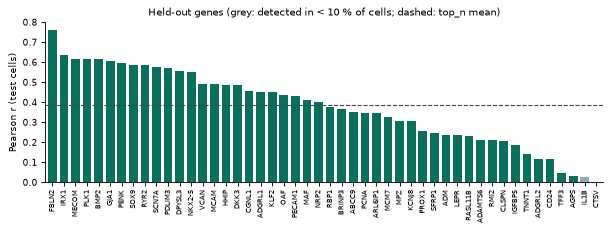

In [7]:
scores = resonate.score_heldout(prep, pred)
for name in ("top_n", "all_heldout"):
    s = scores[name]
    print(f"{name:12s} {s['n_genes']} genes, {s['n_cells']} test cells: mean Pearson {s['pearson']:.3f}")

r = pd.Series(scores["all_heldout"]["per_gene"]["pearson"], index=pred.var_names).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.bar(range(len(r)), r, width=0.75, color=[TEAL if g in scores["top_n_genes"] else "#9aa5b1" for g in r.index])
ax.axhline(scores["top_n"]["pearson"], color="#33485d", lw=1, ls="--")
ax.set_xticks(range(len(r)), r.index, rotation=90, fontsize=6)
ax.set_xlim(-0.6, len(r) - 0.4)
ax.set_ylabel("Pearson r (test cells)")
ax.set_title("Held-out genes (grey: detected in < 10 % of cells; dashed: top_n mean)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In this run the mean Pearson correlation is 0.384 over the 47 `top_n` genes, and it varies widely from gene to gene.

## 5. Measured and predicted maps

The best, the median and the worst of the scored genes; each map is coloured from its 1st to its 99th percentile
(darker is higher).

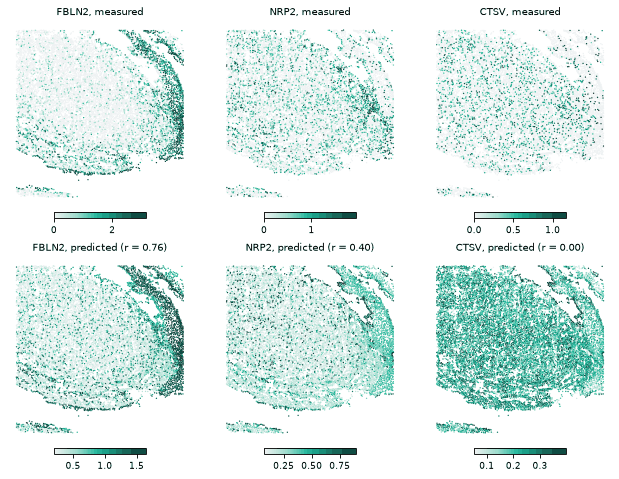

In [8]:
from resonate.metrics import truth_log_expression

truth = pd.DataFrame(truth_log_expression(prep), columns=[str(g) for g in prep.truth_genes])


def expression_map(ax, values, title):
    values = np.asarray(values, dtype=float)
    lo, hi = np.percentile(values, [1, 99])
    order = np.argsort(values)
    dots = ax.scatter(xy[order, 0], xy[order, 1], c=values[order], s=1.5, cmap=RAMP, vmin=lo, vmax=hi, linewidths=0)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.colorbar(dots, cax=ax.inset_axes([0.25, -0.07, 0.5, 0.035]), orientation="horizontal")


top = r[r.index.isin(scores["top_n_genes"])]
show = [top.index[0], top.index[len(top) // 2], top.index[-1]]
fig, axes = plt.subplots(2, 3, figsize=(8, 5.8))
for j, g in enumerate(show):
    expression_map(axes[0, j], truth[g], f"{g}, measured")
    expression_map(axes[1, j], pred[:, g].X.ravel(), f"{g}, predicted (r = {r[g]:.2f})")
fig.tight_layout(h_pad=3)
plt.show()

The colour bars show that the predictions span a narrower range than the measurements, so compare patterns rather than
levels. *CTSV* is not predicted at all (r = 0.00).

## 6. Predict genes outside the panel

Any gene that the reference measures and that has an embedding can be predicted without refitting. These markers,
taken from the reference, are not in the panel. For your own data, keep all measured genes as input and list the genes
you care about in `target_genes`.

(12000, 13) | in the panel: []


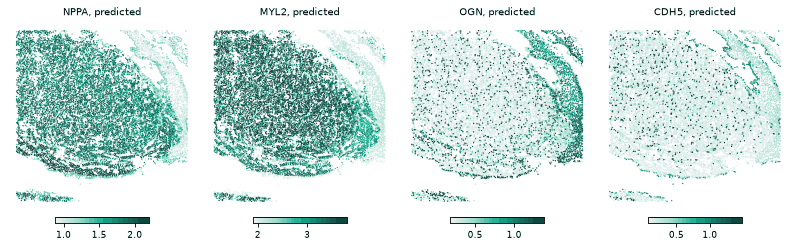

In [9]:
markers = {
    "cardiomyocyte": ["NPPA", "NPPB", "MYL2", "MYL3", "FHL2"],
    "fibroblast": ["OGN", "COL6A2", "MFAP4"],
    "endothelial": ["CDH5", "EGFL7", "EMCN"],
    "pericyte / SMC": ["NDUFA4L2", "COX4I2"],
}
genes = [g for gs in markers.values() for g in gs]
unseen = model.predict(genes, reference=reference, gene_embeddings=emb)
print(unseen.shape, "| in the panel:", [g for g in genes if g in spatial.var_names])

fig, axes = plt.subplots(1, 4, figsize=(10, 3.1))
for ax, g in zip(axes, ["NPPA", "MYL2", "OGN", "CDH5"]):
    expression_map(ax, unseen[:, g].X.ravel(), f"{g}, predicted")
fig.tight_layout()
plt.show()

Predicted *MYL2* is high in the ventricular cardiomyocytes, *OGN* on the right where the fibroblast and valve cells lie,
and *CDH5* in scattered cells and along the lower edge, like the endothelial cells in step 2. *NPPA* is high across the
ventricular cardiomyocytes.

## 7. Predicted expression by cell type

Mean predicted expression per group of spatial cells (left) next to mean measured expression per cell type of the
reference (right); each row is scaled from its lowest (light) to its highest (dark) group.

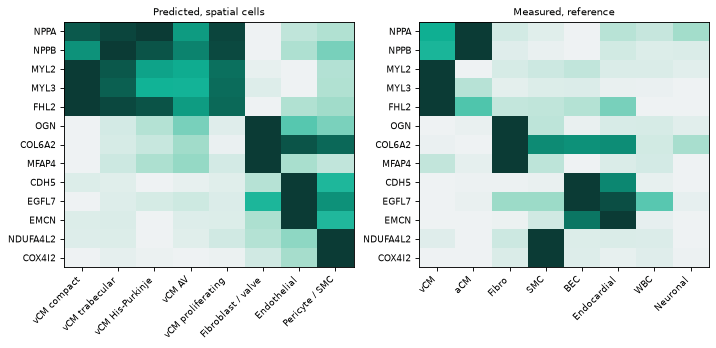

In [10]:
pred_means = unseen.to_df().groupby(group).mean().loc[list(GROUPS)].T

ref_log = reference.copy()
sc.pp.normalize_total(ref_log, target_sum=1e4)
sc.pp.log1p(ref_log)
ref_types = ["vCM", "aCM", "Fibro", "SMC", "BEC", "Endocardial", "WBC", "Neuronal"]
ref_means = ref_log[:, genes].to_df().groupby(reference.obs["author_label"].to_numpy()).mean().loc[ref_types].T

fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, df, title in [(axes[0], pred_means, "Predicted, spatial cells"), (axes[1], ref_means, "Measured, reference")]:
    lo, hi = df.min(axis=1), df.max(axis=1)
    ax.imshow(df.sub(lo, axis=0).div(hi - lo, axis=0).to_numpy(), cmap=RAMP, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns, rotation=45, ha="right")
    ax.set_yticks(range(df.shape[0]), df.index)
    ax.set_title(title)
fig.tight_layout()
plt.show()

For each of the 13 markers, the darkest predicted group is the one that matches the reference: cardiomyocyte genes in
ventricular cardiomyocytes, fibroblast genes in fibroblast and valve cells, endothelial genes in endothelial cells and
the two pericyte genes in pericytes and smooth muscle cells.

## 8. Save

Predictions are AnnData objects. A fitted model is saved with the prepared inputs it was trained on (reloading: see the
[FAQ](https://j041120h.github.io/RESONATE_tutorial/faq/)).

In [11]:
pred.write_h5ad("heldout_predictions.h5ad")
unseen.write_h5ad("outside_panel_predictions.h5ad")
prep.save("prepared")
model.save("model")

**Next:** the same steps from a shell ([command line](https://j041120h.github.io/RESONATE_tutorial/tutorials/cli/)); your own data
([inputs and outputs](https://j041120h.github.io/RESONATE_tutorial/tutorials/inputs_outputs/), [choosing a reference and embeddings](https://j041120h.github.io/RESONATE_tutorial/tutorials/choosing/));
all arguments ([API reference](https://j041120h.github.io/RESONATE_tutorial/api/)).